# TP Jour 4 – UC-08 : Analyse des données, KPI et visualisation
**Retail Intelligence Platform – IPSSI**

- **Groupe :** Paul, Wael
- **Date :** 19/11/2026
- **Parcours UC-07 retenu :** B (local / open source) – MinIO + Apache Iceberg + Spark + Trino

### Objectifs de l'analyse

Question métier issue du Jour 1 : **comment se répartit et évolue le chiffre d'affaires des ventes magasin ?**

1. Mesurer l'activité des ventes magasin (chiffre d'affaires net, quantités, tickets, panier moyen) sur le lot initial TPCx-BB.
2. Observer l'évolution mensuelle des ventes (2001-2005) et comparer les 12 magasins.
3. Identifier les catégories de produits qui contribuent le plus au chiffre d'affaires.
4. Mesurer le volume de retours magasin en précisant ses limites.

Les données TPCx-BB sont **synthétiques** : les résultats illustrent une démarche analytique et ne décrivent pas une entreprise réelle.

## 0. Environnement de référence

| Composant | Version / rôle | Où |
| --- | --- | --- |
| Python | 3.12 | conteneur `lake` (`/opt/venv`, géré par uv) |
| Apache Spark / PySpark | 4.1.4, mode `local[*]` | conteneur `lake` |
| Apache Iceberg | 1.12.0 (runtime Spark), catalogue REST 1.10.1 | `iceberg-rest`, catalogue Spark `iceberg` |
| MinIO | RELEASE.2026-08-04 (stockage objet S3, bucket `warehouse`) | `minio` |
| Trino | 484 (requêtes SQL, catalogue `iceberg`) | `trino` |
| Pandas / Matplotlib | voir cellule suivante | conteneur `lake` |

Démarrage : `docker compose up -d` puis Jupyter `http://localhost:8888/?token=tp`.
**Prérequis :** le notebook `TP4_00_chargement_lakehouse.ipynb` doit avoir été exécuté (il remplit les couches Bronze / Silver / Gold).

In [1]:
import platform
import subprocess
import sys

import matplotlib
import pandas as pd
import pyspark
import trino

java = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0]
print("OS          :", platform.platform())
print("Python      :", sys.version.split()[0], sys.executable)
print("Java        :", java)
print("PySpark     :", pyspark.__version__)
print("Pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("Trino client:", trino.__version__ if hasattr(trino, "__version__") else "installé")

OS          : Linux-7.3.0-cachyos1.fc44.x86_64-x86_64-with-glibc2.41
Python      : 3.12.14 /opt/venv/bin/python
Java        : openjdk version "17.0.19" 2026-04-21
PySpark     : 4.1.4
Pandas      : 2.3.3
Matplotlib  : 3.11.2
Trino client: 0.340.0


In [2]:
conn = trino.dbapi.connect(host="trino", port=8080, user="etudiant", catalog="iceberg")
cur = conn.cursor()
cur.execute("SELECT node_version FROM system.runtime.nodes")
print("Trino       :", cur.fetchone()[0])
cur.execute("SHOW SCHEMAS FROM iceberg")
print("Schémas Iceberg vus par Trino :", sorted(r[0] for r in cur.fetchall() if r[0] != "information_schema"))

Trino       : 484
Schémas Iceberg vus par Trino : ['bronze', 'gold', 'silver', 'system']


## 1. Import des bibliothèques

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## 2. Création de la session Spark

Le catalogue Iceberg (`iceberg`), son URI REST et l'accès à MinIO sont déclarés dans `docker/spark/spark-defaults.conf` : la session n'a pas besoin de les répéter.

In [4]:
spark = (
    SparkSession.builder
    .appName("TP4-Retail-Intelligence")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("Version Spark :", spark.version)
print("Master        :", spark.sparkContext.master)
print("Catalogue     :", spark.conf.get("spark.sql.catalog.iceberg.uri"), "->", spark.conf.get("spark.sql.catalog.iceberg.warehouse"))
for ns in ["bronze", "silver", "gold"]:
    print(f"iceberg.{ns:7s}:", ", ".join(sorted(r.tableName for r in spark.sql(f"SHOW TABLES IN iceberg.{ns}").collect())))

26/11/22 17:34:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Version Spark : 4.1.4
Master        : local[*]
Catalogue     : http://iceberg-rest:8181 -> s3://warehouse/


iceberg.bronze : customer, customer_address, customer_demographics, date_dim, household_demographics, income_band, inventory, item, item_marketprices, product_reviews, promotion, reason, ship_mode, store, store_returns, store_sales, time_dim, warehouse, web_clickstreams, web_page, web_returns, web_sales, web_site
iceberg.silver : date_dim, item, store, store_returns, store_sales
iceberg.gold   : retours_magasin_mensuels, ventes_magasin_mensuelles, ventes_magasin_par_produit


## 3. Chargement des jeux de données

Les jeux viennent du lakehouse Iceberg (MinIO), produits par `TP4_00_chargement_lakehouse.ipynb` à partir des fichiers TPCx-BB du lot initial, avec les règles de nettoyage du Jour 3 (UC-06).

### 3.1 Jeux Silver

| Table | Rôle dans l'analyse |
| --- | --- |
| `iceberg.silver.store_sales` | fait : lignes de ticket des ventes magasin |
| `iceberg.silver.store_returns` | fait : lignes de retour magasin |
| `iceberg.silver.item` | dimension produit (catégorie, classe) |
| `iceberg.silver.store` | dimension magasin |
| `iceberg.silver.date_dim` | dimension calendrier |

In [5]:
df_ventes = spark.table("iceberg.silver.store_sales")
df_retours = spark.table("iceberg.silver.store_returns")
df_produits = spark.table("iceberg.silver.item")
df_magasins = spark.table("iceberg.silver.store")
df_dates = spark.table("iceberg.silver.date_dim")

df_ventes.select("ss_sold_date_sk", "ss_store_sk", "ss_ticket_number", "ss_item_sk", "ss_quantity", "ss_net_paid", "ss_net_profit").show(5)

+---------------+-----------+----------------+----------+-----------+-----------+-------------+
|ss_sold_date_sk|ss_store_sk|ss_ticket_number|ss_item_sk|ss_quantity|ss_net_paid|ss_net_profit|
+---------------+-----------+----------------+----------+-----------+-----------+-------------+
|          36890|         10|               0|     10000|         54|    4500.36|      -856.98|
|          36890|          4|               1|     10413|         84|      31.60|      -290.96|
|          36890|         11|               2|      3963|         94|    2092.44|     -3600.20|
|          36890|          5|               5|      8633|         95|    6840.00|      2421.55|
|          36890|         11|               6|     15336|         52|    2692.56|       902.20|
+---------------+-----------+----------------+----------+-----------+-----------+-------------+
only showing top 5 rows


### 3.2 Jeux Gold

| Table | Granularité |
| --- | --- |
| `iceberg.gold.ventes_magasin_mensuelles` | un magasin × un mois |
| `iceberg.gold.ventes_magasin_par_produit` | un article |
| `iceberg.gold.retours_magasin_mensuels` | un magasin × un mois (date de retour) |

In [6]:
gold_mensuel = spark.table("iceberg.gold.ventes_magasin_mensuelles")
gold_produit = spark.table("iceberg.gold.ventes_magasin_par_produit")
gold_retours = spark.table("iceberg.gold.retours_magasin_mensuels")

gold_mensuel.orderBy("mois", "s_store_sk").show(5)
gold_produit.orderBy(F.desc("ca_net")).show(5)

+-------+----------+----------------+------------+-------+---------+----------+--------+----------+----------+
|   mois|s_store_sk|      s_store_id|s_store_name|s_state|nb_lignes|nb_tickets|quantite|    ca_net|profit_net|
+-------+----------+----------------+------------+-------+---------+----------+--------+----------+----------+
|2001-01|         0|AAAAAAAAAAAAAAAA|      Forest|     CO|      861|       111|   44609|1386332.96|-846846.06|
|2001-01|         1|AAAAAAAAAAAAAAAB|    Hillside|     TN|      932|       129|   47121|1564162.75|-754801.44|
|2001-01|         2|AAAAAAAAAAAAAAAC|    Sherwood|     CA|      810|       113|   42102|1471262.07|-647082.55|
|2001-01|         3|AAAAAAAAAAAAAAAD|     Pioneer|     TX|      987|       133|   49402|1657308.51|-736476.39|
|2001-01|         4|AAAAAAAAAAAAAAAE|     Elmwood|     KY|      950|       133|   48855|1640426.13|-794777.25|
+-------+----------+----------------+------------+-------+---------+----------+--------+----------+----------+
o

## 4. Vérification des schémas et des volumes

Pour chaque jeu : nom exact, provenance, format, schéma, granularité, contrôles qualité disponibles, pertinence pour l'analyse.

In [7]:
jeux = {
    "silver.store_sales": df_ventes,
    "silver.store_returns": df_retours,
    "silver.item": df_produits,
    "silver.store": df_magasins,
    "silver.date_dim": df_dates,
    "gold.ventes_magasin_mensuelles": gold_mensuel,
    "gold.ventes_magasin_par_produit": gold_produit,
    "gold.retours_magasin_mensuels": gold_retours,
}
volumes = pd.DataFrame(
    [(nom, df.count(), len(df.columns)) for nom, df in jeux.items()],
    columns=["jeu", "lignes", "colonnes"],
)
volumes

,jeu,lignes,colonnes
0,silver.store_sales,667579,25
1,silver.store_returns,37902,22
2,silver.item,17820,24
3,silver.store,12,31
4,silver.date_dim,109573,30
5,gold.ventes_magasin_mensuelles,720,10
6,gold.ventes_magasin_par_produit,17820,10
7,gold.retours_magasin_mensuels,948,5


In [8]:
for nom in ["silver.store_sales", "silver.store_returns", "gold.ventes_magasin_mensuelles", "gold.ventes_magasin_par_produit"]:
    print("=====", nom)
    jeux[nom].printSchema()

===== silver.store_sales
root
 |-- ss_sold_date_sk: long (nullable = true)
 |-- ss_sold_time_sk: long (nullable = true)
 |-- ss_item_sk: long (nullable = true)
 |-- ss_customer_sk: long (nullable = true)
 |-- ss_cdemo_sk: long (nullable = true)
 |-- ss_hdemo_sk: long (nullable = true)
 |-- ss_addr_sk: long (nullable = true)
 |-- ss_store_sk: long (nullable = true)
 |-- ss_promo_sk: long (nullable = true)
 |-- ss_ticket_number: long (nullable = true)
 |-- ss_quantity: long (nullable = true)
 |-- ss_wholesale_cost: decimal(15,2) (nullable = true)
 |-- ss_list_price: decimal(15,2) (nullable = true)
 |-- ss_sales_price: decimal(15,2) (nullable = true)
 |-- ss_ext_discount_amt: decimal(15,2) (nullable = true)
 |-- ss_ext_sales_price: decimal(15,2) (nullable = true)
 |-- ss_ext_wholesale_cost: decimal(15,2) (nullable = true)
 |-- ss_ext_list_price: decimal(15,2) (nullable = true)
 |-- ss_ext_tax: decimal(15,2) (nullable = true)
 |-- ss_coupon_amt: decimal(15,2) (nullable = true)
 |-- ss_net_

In [9]:
granularite = df_ventes.agg(
    F.count("*").alias("lignes"),
    F.countDistinct("ss_ticket_number").alias("tickets_distincts"),
    F.countDistinct("ss_store_sk", "ss_ticket_number").alias("couples_magasin_ticket"),
    F.countDistinct("ss_ticket_number", "ss_item_sk").alias("couples_ticket_article"),
    F.countDistinct("ss_customer_sk").alias("clients_distincts"),
).toPandas()
granularite["lignes_par_ticket"] = (granularite["lignes"] / granularite["tickets_distincts"]).round(2)
granularite

,lignes,tickets_distincts,couples_magasin_ticket,couples_ticket_article,clients_distincts,lignes_par_ticket
0,667579,89100,89100,663443,37336,7.49


In [10]:
periode_ventes = (
    df_ventes.join(df_dates, df_ventes.ss_sold_date_sk == df_dates.d_date_sk)
    .agg(F.min("d_date").alias("debut"), F.max("d_date").alias("fin"), F.countDistinct(F.date_format("d_date", "yyyy-MM")).alias("mois"))
    .withColumn("jeu", F.lit("store_sales"))
)
periode_retours = (
    df_retours.join(df_dates, df_retours.sr_returned_date_sk == df_dates.d_date_sk)
    .agg(F.min("d_date").alias("debut"), F.max("d_date").alias("fin"), F.countDistinct(F.date_format("d_date", "yyyy-MM")).alias("mois"))
    .withColumn("jeu", F.lit("store_returns"))
)
periode_ventes.unionByName(periode_retours).select("jeu", "debut", "fin", "mois").toPandas()

,jeu,debut,fin,mois
0,store_sales,2001-01-01,2005-12-13,60
1,store_returns,2001-01-25,2007-11-14,83


### 4.1 Inventaire des jeux utilisés (J4-01)

Provenance commune : kit TPCx-BB fourni (`retail_project/data`, lot initial, fichiers `.dat` séparés par `|`), chargé en Bronze puis nettoyé en Silver par `TP4_00_chargement_lakehouse.ipynb`. Format physique : table Apache Iceberg, fichiers Parquet dans MinIO (`s3://warehouse/`).

| Jeu de données | Zone | Format | Granularité | Lignes | Contrôles qualité | Usage prévu |
|---|---|---|---|---|---|---|
| `store_sales` | Silver | Iceberg / Parquet | une ligne d'article dans un ticket | 667 579 | clés requises non nulles, quantité > 0, doublons exacts, intégrité vers item / store / date_dim | KPI, statistiques |
| `store_returns` | Silver | Iceberg / Parquet | une ligne d'article retourné | 37 902 | clés requises non nulles, quantité retournée > 0, doublons exacts | KPI retours |
| `item` | Silver | Iceberg / Parquet | un article | 17 820 | `i_item_sk` unique et non nul | dimension produit |
| `store` | Silver | Iceberg / Parquet | un magasin | 12 | `s_store_sk` unique | dimension magasin |
| `date_dim` | Silver | Iceberg / Parquet | un jour | 109 573 | `d_date_sk` unique, `d_date` non nul | dimension calendrier |
| `ventes_magasin_mensuelles` | Gold | Iceberg / Parquet | un magasin × un mois | 720 | Σ lignes et Σ CA = Silver | analyse temporelle, comparaison magasins |
| `ventes_magasin_par_produit` | Gold | Iceberg / Parquet | un article | 17 820 | Σ lignes et Σ CA = Silver | analyse produits / catégories |
| `retours_magasin_mensuels` | Gold | Iceberg / Parquet | un magasin × un mois de retour | 948 | — | volume de retours |

Pertinence : ces jeux sont ceux de la question métier du Jour 1 (CA des ventes magasin) et disposent d'une date exploitable, d'un magasin et d'une catégorie produit vérifiés par jointure.

### 4.2 Qualité : valeurs manquantes, doublons, anomalies

In [11]:
def valeurs_manquantes(df, colonnes):
    total = df.count()
    ligne = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in colonnes]).first()
    return pd.DataFrame(
        [(c, ligne[c], round(100 * ligne[c] / total, 2)) for c in colonnes],
        columns=["colonne", "nulls", "pct"],
    )

valeurs_manquantes(df_ventes, [
    "ss_sold_date_sk", "ss_store_sk", "ss_ticket_number", "ss_item_sk", "ss_customer_sk",
    "ss_promo_sk", "ss_hdemo_sk", "ss_addr_sk", "ss_quantity", "ss_net_paid", "ss_net_profit",
])

,colonne,nulls,pct
0,ss_sold_date_sk,0,0.00
1,ss_store_sk,0,0.00
2,ss_ticket_number,0,0.00
3,ss_item_sk,0,0.00
4,ss_customer_sk,0,0.00
5,ss_promo_sk,158,0.02
6,ss_hdemo_sk,295,0.04
7,ss_addr_sk,448,0.07
8,ss_quantity,0,0.00
9,ss_net_paid,0,0.00


In [12]:
nb_doublons = df_ventes.count() - df_ventes.dropDuplicates().count()
anomalies = df_ventes.agg(
    F.lit(nb_doublons).alias("doublons_exacts"),
    F.sum((F.col("ss_quantity") <= 0).cast("int")).alias("quantite_non_positive"),
    F.sum((F.col("ss_net_paid") < 0).cast("int")).alias("ca_net_negatif"),
    F.sum((F.col("ss_net_paid") == 0).cast("int")).alias("ca_net_nul"),
    F.sum((F.col("ss_net_profit") < 0).cast("int")).alias("profit_negatif"),
).toPandas()
anomalies["pct_profit_negatif"] = round(100 * anomalies["profit_negatif"] / df_ventes.count(), 1)
anomalies

,doublons_exacts,quantite_non_positive,ca_net_negatif,ca_net_nul,profit_negatif,pct_profit_negatif
0,0,0,0,3954,495971,74.3


In [13]:
orphelins = pd.DataFrame([
    ("store_sales -> item", df_ventes.join(df_produits, df_ventes.ss_item_sk == df_produits.i_item_sk, "left_anti").count()),
    ("store_sales -> store", df_ventes.join(df_magasins, df_ventes.ss_store_sk == df_magasins.s_store_sk, "left_anti").count()),
    ("store_sales -> date_dim", df_ventes.join(df_dates, df_ventes.ss_sold_date_sk == df_dates.d_date_sk, "left_anti").count()),
    ("store_returns -> store_sales (ticket)", df_retours.join(df_ventes, df_retours.sr_ticket_number == df_ventes.ss_ticket_number, "left_anti").count()),
], columns=["relation", "orphelins"])
orphelins

,relation,orphelins
0,store_sales -> item,0
1,store_sales -> store,0
2,store_sales -> date_dim,0
3,store_returns -> store_sales (ticket),0


**Constats qualité :**

- Aucune clé manquante sur les colonnes utilisées par les KPI (date, magasin, ticket, article, quantité, montant net) ; les clés secondaires (client, promotion, foyer, adresse) peuvent être vides et ne sont pas utilisées.
- Aucun doublon exact, aucune quantité nulle ou négative, aucun montant net négatif.
- 3 954 lignes (0,6 %) ont un montant net égal à 0 : elles sont conservées (quantité vendue réelle, montant nul possible après remise ou coupon) et comptent dans les quantités et les tickets.
- Toutes les ventes retrouvent leur article, leur magasin et leur date : les jointures ne perdent ni ne multiplient de lignes.
- `ss_net_profit` est négatif sur environ trois lignes sur quatre : caractéristique du générateur synthétique. Le profit n'est donc **pas** retenu comme indicateur de marge.
- Le couple (ticket, article) n'est pas unique : une jointure retours → ventes sur ce couple multiplierait des lignes. Les retours sont donc analysés séparément, par date de retour.
- Les retours couvrent 2001-01 à 2007-11 alors que les ventes s'arrêtent en 2005-12 : un taux de retour mensuel n'a de sens que sur la période commune.

## 5. Dictionnaire des KPI (J4-02)

KPI retenus (calculables et vérifiés sur les données disponibles) :

| KPI | Définition métier | Formule | Champs utilisés | Filtres | Granularité | Unité | Limites |
|---|---|---|---|---|---|---|---|
| **CA net magasin** | Montant net encaissé sur les ventes magasin, hors taxes | `SUM(ss_net_paid)` | `store_sales.ss_net_paid` | lot initial, lignes Silver | total, par mois, par magasin, par catégorie | unité monétaire du fichier (non précisée par le kit) | hors taxes ; hors ventes web ; données synthétiques |
| **Quantités vendues** | Nombre d'unités d'articles vendues | `SUM(ss_quantity)` | `store_sales.ss_quantity` | `ss_quantity > 0` | total, par mois, par magasin, par catégorie | unités | ≠ nombre de lignes, ≠ nombre de tickets |
| **Nombre de tickets** | Nombre de passages en caisse | `COUNT(DISTINCT ss_ticket_number)` | `store_sales.ss_ticket_number` | lot initial | total, par mois, par magasin | tickets | un ticket = un magasin (vérifié : 89 100 tickets = 89 100 couples magasin/ticket) |
| **Panier moyen** | CA net moyen par ticket | `SUM(ss_net_paid) / COUNT(DISTINCT ss_ticket_number)` | `ss_net_paid`, `ss_ticket_number` | lot initial | total, par magasin, par mois | unité monétaire / ticket | calculé sur les tickets, **pas** sur les lignes (≈ 7,5 lignes par ticket) |
| **Volume de retours** | Unités et montant retournés en magasin | `SUM(sr_return_quantity)`, `SUM(sr_return_amt)` | `store_returns` | date de retour | par mois de retour, par magasin | unités, unité monétaire | rattaché à la date de retour, pas à la date de vente ; retours jusqu'en 2007-11 |
| **Taux de retour (quantité)** | Part des unités vendues retournées | `SUM(sr_return_quantity) / SUM(ss_quantity)` | `sr_return_quantity`, `ss_quantity` | numérateur : retours datés 2001-01 → 2005-12 ; dénominateur : ventes de la même période | période entière ou par magasin | % | numérateur et dénominateur sur des dates différentes (retour vs vente) : indicateur approché |

**KPI non retenus :**

| KPI | Raison |
|---|---|
| Marge | `ss_net_profit` est négatif sur ~74 % des lignes (génération synthétique) et les coûts ne sont pas qualifiés : la marge ne serait pas interprétable. |
| Répartition par canal | Le canal n'est pas une colonne : seule la séparation magasin (`store_sales`) / web (`web_sales`) existe. Hors périmètre de cette analyse magasin. |
| Panier moyen par client | `ss_customer_sk` est renseigné mais la fidélité des clients synthétiques n'est pas vérifiée. |

## 6. Calcul des KPI

Calculs sur les jeux Silver (lot initial). Montants dans l'unité du fichier, non précisée par le kit.

In [14]:
OUT = Path("/opt/tp/Jour4")
RES = OUT / "preuves" / "uc08"
VIZ = OUT / "visualisations"
for d in (RES, VIZ):
    d.mkdir(parents=True, exist_ok=True)

dates = df_dates.select("d_date_sk", "d_date")
ventes_d = df_ventes.join(dates, df_ventes.ss_sold_date_sk == dates.d_date_sk)
retours_d = df_retours.join(dates, df_retours.sr_returned_date_sk == dates.d_date_sk)
DEBUT, FIN = [str(v) for v in ventes_d.agg(F.min("d_date"), F.max("d_date")).first()]
print("période des ventes :", DEBUT, "->", FIN)

période des ventes : 2001-01-01 -> 2005-12-13


### KPI 1 – CA net magasin et quantités vendues

In [15]:
k = df_ventes.agg(
    F.sum("ss_net_paid").alias("ca_net"),
    F.sum("ss_quantity").alias("quantites"),
    F.count("*").alias("lignes"),
    F.countDistinct("ss_ticket_number").alias("tickets"),
).first()
ca_net = float(k["ca_net"])
print(f"CA net magasin    : {ca_net:,.2f}")
print(f"Quantités vendues : {k['quantites']:,} unités")
print(f"Lignes de vente   : {k['lignes']:,}  (≠ quantités, ≠ tickets)")

CA net magasin    : 1,150,529,586.37
Quantités vendues : 33,755,474 unités
Lignes de vente   : 667,579  (≠ quantités, ≠ tickets)


### KPI 2 – Nombre de tickets et panier moyen

In [16]:
panier = ca_net / k["tickets"]
print(f"Tickets distincts    : {k['tickets']:,}")
print(f"Panier moyen         : {panier:,.2f} par ticket")
print(f"Lignes par ticket    : {k['lignes'] / k['tickets']:.2f}")
print(f"Unités par ticket    : {k['quantites'] / k['tickets']:.1f}")
print(f"Panier faux (/ligne) : {ca_net / k['lignes']:,.2f}  <- à ne pas utiliser")

Tickets distincts    : 89,100
Panier moyen         : 12,912.79 par ticket
Lignes par ticket    : 7.49
Unités par ticket    : 378.8
Panier faux (/ligne) : 1,723.44  <- à ne pas utiliser


### KPI 3 – Retours magasin et taux de retour

In [17]:
r_tout = retours_d.agg(F.count("*").alias("n"), F.sum("sr_return_quantity").alias("q"), F.sum("sr_return_amt").alias("m")).first()
r_com = retours_d.filter(F.col("d_date").between(DEBUT, FIN)).agg(
    F.count("*").alias("n"), F.sum("sr_return_quantity").alias("q"), F.sum("sr_return_amt").alias("m")).first()
taux_retour = r_com["q"] / k["quantites"]
print(f"Retours, toute période    : {r_tout['n']:,} lignes, {r_tout['q']:,} unités, {float(r_tout['m']):,.2f}")
print(f"Retours, {DEBUT} -> {FIN} : {r_com['n']:,} lignes, {r_com['q']:,} unités, {float(r_com['m']):,.2f}")
print(f"Taux de retour (quantité, période commune) : {taux_retour:.2%}")

Retours, toute période    : 37,902 lignes, 972,092 unités, 36,688,696.43
Retours, 2001-01-01 -> 2005-12-13 : 30,313 lignes, 777,567 unités, 29,285,241.45
Taux de retour (quantité, période commune) : 2.30%


### Export des KPI (`Jour4/preuves/uc08/kpi.csv`)

In [18]:
kpi = pd.DataFrame([
    ("CA net magasin", round(ca_net, 2), "unité monétaire", "SUM(ss_net_paid)", "lot initial"),
    ("Quantités vendues", k["quantites"], "unités", "SUM(ss_quantity)", "lot initial"),
    ("Nombre de tickets", k["tickets"], "tickets", "COUNT(DISTINCT ss_ticket_number)", "lot initial"),
    ("Panier moyen", round(panier, 2), "unité monétaire / ticket", "CA net / tickets", "lot initial"),
    ("Quantité retournée", r_com["q"], "unités", "SUM(sr_return_quantity)", f"retours datés {DEBUT} -> {FIN}"),
    ("Montant retourné", round(float(r_com["m"]), 2), "unité monétaire", "SUM(sr_return_amt)", f"retours datés {DEBUT} -> {FIN}"),
    ("Taux de retour (quantité)", round(100 * taux_retour, 2), "%", "quantité retournée / quantités vendues", "période commune"),
], columns=["kpi", "valeur", "unite", "formule", "perimetre"], dtype=object)
kpi.to_csv(RES / "kpi.csv", index=False)
kpi

,kpi,valeur,unite,formule,perimetre
0,CA net magasin,1150529586.37,unité monétaire,SUM(ss_net_paid),lot initial
1,Quantités vendues,33755474,unités,SUM(ss_quantity),lot initial
2,Nombre de tickets,89100,tickets,COUNT(DISTINCT ss_ticket_number),lot initial
3,Panier moyen,12912.79,unité monétaire / ticket,CA net / tickets,lot initial
4,Quantité retournée,777567,unités,SUM(sr_return_quantity),retours datés 2001-01-01 -> 2005-12-13
5,Montant retourné,29285241.45,unité monétaire,SUM(sr_return_amt),retours datés 2001-01-01 -> 2005-12-13
6,Taux de retour (quantité),2.3,%,quantité retournée / quantités vendues,période commune


## 7. Statistiques descriptives (J4-03)

Trois niveaux : la ligne de vente, le ticket, le couple magasin × mois (Gold).

In [19]:
def decrire(df, niveau, colonnes):
    lignes = []
    for c in colonnes:
        s = df.agg(F.count(c).alias("n"), F.min(c).alias("min"), F.max(c).alias("max"),
                   F.avg(c).alias("moyenne"), F.median(c).alias("mediane"), F.sum(c).alias("somme")).first()
        lignes.append((niveau, c, s["n"], float(s["min"]), float(s["max"]), round(float(s["moyenne"]), 2),
                       round(float(s["mediane"]), 2), round(float(s["somme"]), 2)))
    return lignes

tickets = df_ventes.groupBy("ss_ticket_number").agg(
    F.sum("ss_net_paid").alias("ca_ticket"), F.count("*").alias("lignes_ticket"), F.sum("ss_quantity").alias("unites_ticket"))
stats = pd.DataFrame(
    decrire(df_ventes, "ligne de vente", ["ss_quantity", "ss_sales_price", "ss_net_paid"])
    + decrire(tickets, "ticket", ["ca_ticket", "lignes_ticket", "unites_ticket"])
    + decrire(gold_mensuel, "magasin x mois", ["ca_net", "nb_tickets"]),
    columns=["niveau", "mesure", "n", "min", "max", "moyenne", "mediane", "somme"],
)
gold_mensuel.orderBy("ca_net").select("mois", "s_store_name", "ca_net").show(3)
stats

+-------+------------+---------+
|   mois|s_store_name|   ca_net|
+-------+------------+---------+
|2005-12|     Elmwood|504366.43|
|2005-12|       Egypt|528501.03|
|2005-12|     Bedford|534424.78|
+-------+------------+---------+
only showing top 3 rows


,niveau,mesure,n,min,max,moyenne,mediane,somme
0,ligne de vente,ss_quantity,667579,1.00,100.00,50.56,51.00,3.375547e+07
1,ligne de vente,ss_sales_price,667579,0.00,199.30,37.86,27.69,2.527701e+07
2,ligne de vente,ss_net_paid,667579,0.00,18745.00,1723.44,878.54,1.150530e+09
3,ticket,ca_ticket,89100,0.00,64785.95,12912.79,11645.15,1.150530e+09
4,ticket,lignes_ticket,89100,1.00,14.00,7.49,7.00,6.675790e+05
5,ticket,unites_ticket,89100,1.00,1143.00,378.85,372.00,3.375547e+07
6,magasin x mois,ca_net,720,504366.43,2169330.60,1597957.76,1612660.69,1.150530e+09
7,magasin x mois,nb_tickets,720,39.00,163.00,123.75,124.00,8.910000e+04


In [20]:
par_annee = (
    gold_mensuel.withColumn("annee", F.substring("mois", 1, 4))
    .groupBy("annee").agg(F.countDistinct("mois").alias("mois"), F.sum("ca_net").alias("ca_net"),
                          F.sum("nb_tickets").alias("tickets"), F.sum("quantite").alias("quantite"))
    .orderBy("annee").toPandas()
)
par_annee["ca_net"] = par_annee["ca_net"].astype(float)
par_annee["ca_net_moyen_mensuel"] = (par_annee["ca_net"] / par_annee["mois"]).round(2)
par_annee

,annee,mois,ca_net,tickets,quantite,ca_net_moyen_mensuel
0,2001,12,2.324987e+08,17991,6814234,19374888.32
1,2002,12,2.309473e+08,17990,6825340,19245605.48
2,2003,12,2.335752e+08,17990,6820308,19464598.80
3,2004,12,2.343449e+08,18039,6887086,19528744.52
4,2005,12,2.191635e+08,17090,6408506,18263628.40


In [21]:
par_categorie = (
    gold_produit.groupBy("i_category")
    .agg(F.count("*").alias("articles"), F.sum("nb_lignes").alias("lignes"),
         F.sum("quantite").alias("quantite"), F.sum("ca_net").alias("ca_net"))
    .toPandas()
)
par_categorie["ca_net"] = par_categorie["ca_net"].astype(float)
par_categorie["part_ca_pct"] = (100 * par_categorie["ca_net"] / par_categorie["ca_net"].sum()).round(2)
par_categorie["part_articles_pct"] = (100 * par_categorie["articles"] / par_categorie["articles"].sum()).round(2)
par_categorie = par_categorie.sort_values("ca_net", ascending=False).reset_index(drop=True)
par_categorie

,i_category,articles,lignes,quantite,ca_net,part_ca_pct,part_articles_pct
0,Music,8143,301236,15238374,5.196667e+08,45.17,45.70
1,Books,5335,177671,9007511,3.071515e+08,26.70,29.94
2,Movies & TV,1286,43376,2189279,7.473589e+07,6.50,7.22
3,Clothing & Accessories,610,32372,1640550,5.675486e+07,4.93,3.42
4,Electronics,692,32619,1632098,5.571509e+07,4.84,3.88
5,Home & Kitchen,476,24380,1226839,4.126051e+07,3.59,2.67
6,Sports & Outdoors,465,23911,1209305,4.092694e+07,3.56,2.61
7,Toys & Games,405,16121,809999,2.743783e+07,2.38,2.27
8,Tools & Home Improvement,408,15893,801519,2.688028e+07,2.34,2.29


### Export (`Jour4/preuves/uc08/statistiques.csv`)

In [22]:
stats.to_csv(RES / "statistiques.csv", index=False)
par_annee.to_csv(RES / "repartition_par_annee.csv", index=False)
par_categorie.to_csv(RES / "repartition_par_categorie.csv", index=False)
print(sorted(p.name for p in RES.iterdir()))

['analyse1_ca_mensuel.csv', 'analyse2_ca_par_categorie.csv', 'co01_comparaison_magasins.csv', 'kpi.csv', 'repartition_par_annee.csv', 'repartition_par_categorie.csv', 'statistiques.csv']


**Commentaire :** les statistiques distinguent bien la ligne, le ticket et le magasin × mois.
La médiane est utilisée à côté de la moyenne car les montants par ligne sont dissymétriques.

**Lecture :**

| Niveau | Constat |
|---|---|
| Ligne de vente | quantité de 1 à 100 (médiane 51) ; montant net médian 878,54 < moyenne 1 723,44 : distribution étirée vers les gros montants |
| Ticket | 7,49 lignes et 379 unités en moyenne ; CA médian 11 645,15, moyen 12 912,79 |
| Magasin × mois | CA de 0,50 M à 2,17 M ; le minimum vient de décembre 2005, mois partiel (cellule ci-dessus) |
| Année | 2001 à 2004 : 230,9 à 234,3 M ; 2005 : 219,2 M car les ventes s'arrêtent le 13/12 |
| Catégorie | Music 45,2 % et Books 26,7 % du CA |

## 8. Préparation des dossiers d'export

Fait en section 6 : `Jour4/preuves/uc08/` (CSV) et `Jour4/visualisations/` (PNG).
Style commun des graphiques ci-dessous.

In [23]:
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
SOURCE = "Source : TPCx-BB synthétique, lot initial, Gold Iceberg (store_sales)"

## 9. Analyse métier n°1 (J4-04)

- **Question métier :** comment évolue le CA net des ventes magasin dans le temps ? (Direction générale, Jour 1)
- **Données utilisées :** `iceberg.gold.ventes_magasin_mensuelles` (magasin × mois).
- **Méthode de calcul :** somme de `ca_net` et de `nb_tickets` par mois, tous magasins ; comparaison par année et par mois calendaire sur les années complètes 2001-2004.

In [24]:
mensuel = (
    gold_mensuel.groupBy("mois").agg(F.sum("ca_net").alias("ca_net"), F.sum("nb_tickets").alias("tickets"),
                                     F.sum("quantite").alias("quantite"))
    .orderBy("mois").toPandas()
)
mensuel["ca_net"] = mensuel["ca_net"].astype(float)
mensuel["panier_moyen"] = (mensuel["ca_net"] / mensuel["tickets"]).round(2)
mensuel.to_csv(RES / "analyse1_ca_mensuel.csv", index=False)
complet = mensuel[mensuel["mois"] < "2005-12"]
print("mois :", len(mensuel), "| dernier mois :", mensuel["mois"].iloc[-1], "(partiel : ventes jusqu'au", FIN + ")")
print(complet["ca_net"].describe().round(0))
print("mois le plus haut :", complet.loc[complet["ca_net"].idxmax(), ["mois", "ca_net"]].tolist())
print("mois le plus bas  :", complet.loc[complet["ca_net"].idxmin(), ["mois", "ca_net"]].tolist())
print("coefficient de variation mensuel :", round(complet["ca_net"].std() / complet["ca_net"].mean(), 3))

mois : 60 | dernier mois : 2005-12 (partiel : ventes jusqu'au 2005-12-13)
count          59.0
mean     19363583.0
std        612705.0
min      17591924.0
25%      18995256.0
50%      19419809.0
75%      19772792.0
max      20632953.0
Name: ca_net, dtype: float64
mois le plus haut : ['2003-10', np.float64(20632952.65)]
mois le plus bas  : ['2002-02', np.float64(17591923.52)]
coefficient de variation mensuel : 0.032


In [25]:
saison = complet[complet["mois"] < "2005-01"].copy()
saison["mois_cal"] = saison["mois"].str[5:]
saison = saison.groupby("mois_cal")["ca_net"].mean().round(0)
(saison / saison.mean() * 100).round(1).rename("indice_saisonnier (100 = moyenne)")

mois_cal
01    100.6
02     93.1
03    102.0
04     98.1
05    101.5
06     98.9
07    102.8
08    101.8
09     98.5
10    102.9
11     98.4
12    101.3
Name: indice_saisonnier (100 = moyenne), dtype: float64

**Résultats :** CA net mensuel moyen 19,36 M sur les 59 mois complets ; écart type 0,61 M (coefficient de variation 3,2 %). Plus haut : 2003-10 (20,63 M). Plus bas : 2002-02 (17,59 M). Décembre 2005 : 8,08 M pour 13 jours.

**Interprétation :** l'indice saisonnier suit le nombre de jours du mois (février 93, mois de 31 jours ≈ 102). Le CA par jour est donc quasi constant : pas de tendance ni de saisonnalité commerciale. C'est le comportement attendu d'un générateur synthétique.

**Limites :** mois de longueurs différentes ; décembre 2005 partiel ; lot refresh (fin décembre 2005) non intégré à Silver.

## 10. Visualisation n°1 (J4-05)

Courbe du CA net mensuel, tous magasins. Export `Jour4/visualisations/visualisation_1_ca_mensuel.png`.

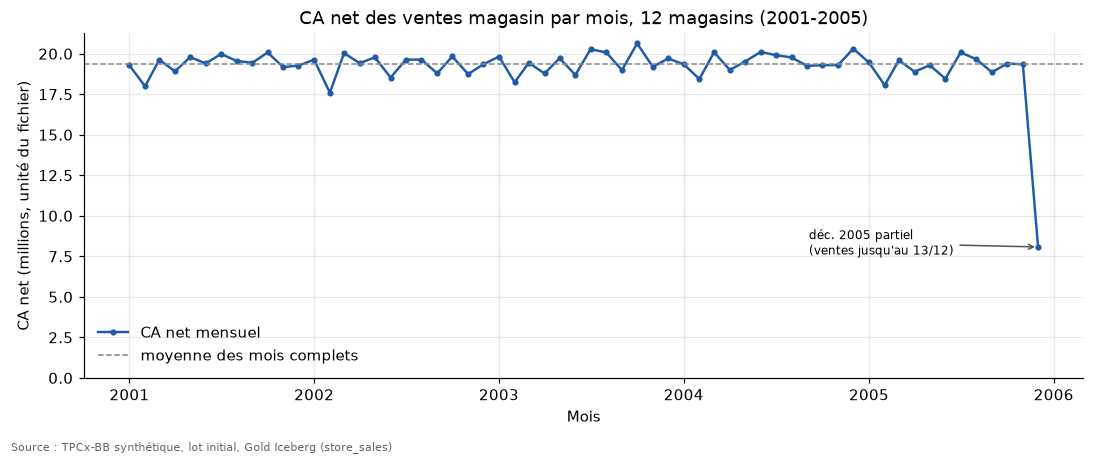

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.2))
x = pd.to_datetime(mensuel["mois"])
ax.plot(x, mensuel["ca_net"] / 1e6, marker="o", ms=3, lw=1.6, color="#1f5aa6", label="CA net mensuel")
ax.axhline(complet["ca_net"].mean() / 1e6, color="#888", ls="--", lw=1, label="moyenne des mois complets")
ax.annotate("déc. 2005 partiel\n(ventes jusqu'au 13/12)", xy=(x.iloc[-1], mensuel["ca_net"].iloc[-1] / 1e6),
            xytext=(-150, -5), textcoords="offset points", fontsize=8, arrowprops=dict(arrowstyle="->", color="#555"))
ax.set_title("CA net des ventes magasin par mois, 12 magasins (2001-2005)")
ax.set_xlabel("Mois")
ax.set_ylabel("CA net (millions, unité du fichier)")
ax.set_ylim(bottom=0)
ax.legend(loc="lower left", frameon=False)
fig.text(0.01, 0.01, SOURCE, fontsize=7, color="#666")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(VIZ / "visualisation_1_ca_mensuel.png")
plt.show()

**Source :** `iceberg.gold.ventes_magasin_mensuelles`, somme des 12 magasins.

**Ce que montre le graphique :** une série plate autour de 19,4 M par mois, avec des creux en février. La chute finale n'est pas une baisse d'activité : décembre 2005 ne compte que 13 jours de ventes.

## 11. Analyse métier n°2 (J4-04)

- **Question métier :** quelles catégories et quels produits portent le CA ? (Direction commerciale, Jour 1)
- **Données utilisées :** `iceberg.gold.ventes_magasin_par_produit` (un article).
- **Méthode de calcul :** somme de `ca_net` par `i_category`, part dans le total ; concentration : part du CA des 4 premiers articles et des 10 % d'articles les plus vendeurs.

In [27]:
par_categorie.to_csv(RES / "analyse2_ca_par_categorie.csv", index=False)
par_categorie[["i_category", "articles", "part_articles_pct", "ca_net", "part_ca_pct"]]

,i_category,articles,part_articles_pct,ca_net,part_ca_pct
0,Music,8143,45.70,5.196667e+08,45.17
1,Books,5335,29.94,3.071515e+08,26.70
2,Movies & TV,1286,7.22,7.473589e+07,6.50
3,Clothing & Accessories,610,3.42,5.675486e+07,4.93
4,Electronics,692,3.88,5.571509e+07,4.84
5,Home & Kitchen,476,2.67,4.126051e+07,3.59
6,Sports & Outdoors,465,2.61,4.092694e+07,3.56
7,Toys & Games,405,2.27,2.743783e+07,2.38
8,Tools & Home Improvement,408,2.29,2.688028e+07,2.34


In [28]:
articles = gold_produit.select("i_item_sk", "i_category", "ca_net").toPandas()
articles["ca_net"] = articles["ca_net"].astype(float)
articles = articles.sort_values("ca_net", ascending=False).reset_index(drop=True)
total = articles["ca_net"].sum()
top4 = articles.head(4)
n10 = int(len(articles) * 0.10)
print("top 4 articles :", top4["i_item_sk"].tolist(), "->", round(100 * top4["ca_net"].sum() / total, 2), "% du CA")
print(f"top 10 % ({n10} articles) :", round(100 * articles.head(n10)["ca_net"].sum() / total, 2), "% du CA")
print("articles sans vente :", int((articles["ca_net"] == 0).sum()))
print("CA médian par article :", round(articles["ca_net"].median(), 2))

top 4 articles : [10000, 10003, 10001, 10002] -> 5.02 % du CA
top 10 % (1782 articles) : 53.22 % du CA
articles sans vente : 0
CA médian par article : 34949.04


**Résultats :** Music (45,2 %) et Books (26,7 %) portent 71,9 % du CA. La part du CA de chaque catégorie est proche de sa part d'articles au catalogue (Music : 45,7 % des articles). Les 4 articles 10000 à 10003 font à eux seuls 5,0 % du CA : chacun pèse 367 à 441 fois le CA médian d'un article (34 949).

**Interprétation :** le CA d'une catégorie dépend surtout du nombre d'articles qu'elle contient, pas d'une meilleure performance unitaire. Les 4 articles hors norme ressemblent à un artefact du générateur (identifiants consécutifs).

**Limites :** libellés produit synthétiques ; les coûts ne sont pas qualifiés, donc pas de marge par catégorie.

## 12. Visualisation n°2 (J4-05)

Barres horizontales : CA net par catégorie et part du total. Export `Jour4/visualisations/visualisation_2_ca_categorie.png`.

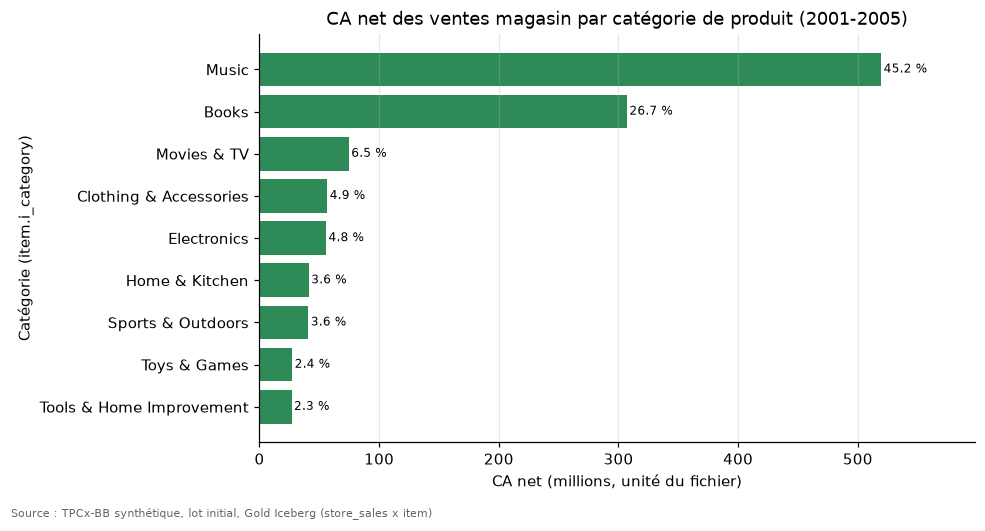

In [29]:
d = par_categorie.sort_values("ca_net")
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(d["i_category"], d["ca_net"] / 1e6, color="#2e8b57")
for b, p in zip(bars, d["part_ca_pct"]):
    ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2, f"{p:.1f} %", va="center", fontsize=8)
ax.set_title("CA net des ventes magasin par catégorie de produit (2001-2005)")
ax.set_xlabel("CA net (millions, unité du fichier)")
ax.set_ylabel("Catégorie (item.i_category)")
ax.set_xlim(0, d["ca_net"].max() / 1e6 * 1.15)
ax.grid(axis="y", visible=False)
fig.text(0.01, 0.01, SOURCE.replace("store_sales", "store_sales x item"), fontsize=7, color="#666")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(VIZ / "visualisation_2_ca_categorie.png")
plt.show()

**Source :** `iceberg.gold.ventes_magasin_par_produit`, regroupé par `i_category`.

**Ce que montre le graphique :** deux catégories dominent ; les sept autres pèsent chacune moins de 7 %. À lire avec la colonne `part_articles_pct` du tableau : l'écart vient surtout de la taille de l'assortiment.

## 13. Interprétation et limites – Constats (J4-06)

Rappel : corrélation ≠ causalité ; les données TPCx-BB sont synthétiques.

### Constat 1 – Activité stable, sans saisonnalité
- **Résultat observé :** CA net mensuel de 19,36 M en moyenne, coefficient de variation 3,2 % ; l'écart d'un mois à l'autre suit le nombre de jours.
- **Interprétation possible :** rythme de vente journalier constant sur cinq ans.
- **Limite :** générateur synthétique ; décembre 2005 partiel ; pas d'objectif ni de budget pour comparer.
- **Recommandation :** suivre le CA par jour plutôt que par mois ; exclure les mois partiels des comparaisons ; charger le lot refresh pour compléter décembre 2005.

### Constat 2 – Le CA suit la taille de l'assortiment
- **Résultat observé :** Music et Books = 71,9 % du CA et 75,6 % des articles ; 4 articles concentrent 5,0 % du CA.
- **Interprétation possible :** l'assortiment explique la répartition ; les 4 articles atypiques méritent une vérification.
- **Limite :** marge non calculable ; association observée, pas une cause démontrée.
- **Recommandation :** comparer les catégories au CA par article ; contrôler les articles 10000 à 10003 avant toute décision d'assortiment.

### Constat 3 – Magasins homogènes (CO-01, section 18)
- **Résultat observé :** 12 magasins entre 94,0 M et 99,0 M (écart 5,2 %), panier moyen de 12 723 à 13 027, taux de retour de 2,16 % à 2,51 %.
- **Interprétation possible :** aucun magasin ne décroche.
- **Limite :** ni surface ni effectif : pas de CA au m² ou par vendeur.
- **Recommandation :** ajouter ces données de référence avant de classer les magasins.

## 14. Conclusion et recommandations

| KPI | Valeur (lot initial) |
|---|---|
| CA net magasin | 1 150 529 586,37 |
| Quantités vendues | 33 755 474 unités |
| Tickets | 89 100 |
| Panier moyen | 12 912,79 par ticket |
| Taux de retour (quantité, 2001-01-01 → 2005-12-13) | 2,30 % |

Le CA est identique aux contrôles du Jour 1 et du Jour 3 : la chaîne Raw → Silver → Gold ne perd aucune ligne.

Recommandations : (1) analyser le CA par jour et exclure les mois partiels ; (2) intégrer le lot refresh à Silver avec une règle de dédoublonnage ; (3) qualifier les coûts avant toute marge ; (4) obtenir surface et objectifs des magasins pour une comparaison utile.

## 15. Instructions de reproduction

1. `docker compose up -d` à la racine du dépôt (HDFS, NiFi, Jupyter, MinIO, Iceberg REST, Trino).
2. Exécuter `notebooks/TP4_00_chargement_lakehouse.ipynb` : remplit Bronze / Silver / Gold dans Iceberg.
3. Exécuter ce notebook de haut en bas (Jupyter `http://localhost:8888/?token=tp`), ou :
   `docker compose exec lake jupyter nbconvert --to notebook --execute --inplace /home/etudiant/notebooks/TP4_Retail_Intelligence.ipynb`
4. Sorties : `Jour4/preuves/uc08/*.csv` et `Jour4/visualisations/*.png`.

## 16. Tests UC-08

| Contrôle | État | Preuve |
|---|---|---|
| Les jeux de données utilisés sont identifiés. | ☑ | section 3, inventaire 4.1 |
| Les schémas et granularités ont été vérifiés. | ☑ | sections 4 et 4.2 |
| Les KPI disposent d'une définition explicite. | ☑ | dictionnaire section 5 |
| Les calculs sont reproductibles. | ☑ | ce notebook, section 15 |
| Les statistiques sont cohérentes avec les données. | ☑ | Σ Gold = Σ Silver (TP4_00), section 7 |
| Les visualisations sont lisibles et légendées. | ☑ | `Jour4/visualisations/` |
| Les interprétations sont justifiées. | ☑ | sections 9 à 13 |
| Les limites des données sont mentionnées. | ☑ | sections 4.2 et 13 |

## 17. Questions de recul

| # | Question | Réponse |
|---|---|---|
| 1 | Pourquoi vérifier la granularité avant un KPI ? | Une ligne est un article d'un ticket. Diviser le CA par les lignes donne un « panier » de 1 723 au lieu de 12 913. |
| 2 | Lignes vs transactions ? | 667 579 lignes, 89 100 tickets, 33,8 M unités : trois grandeurs différentes. |
| 3 | Limites rencontrées ? | Données synthétiques, unité monétaire inconnue, profit négatif sur 74 % des lignes, décembre 2005 partiel, retours datés jusqu'en 2007. |
| 4 | KPI non calculés ? | Marge (coûts non qualifiés), part du canal web (web_sales hors Silver), stock magasin (absent du kit), conversion des clics (pas d'identifiant fiable). |
| 5 | Vérification de la cohérence ? | Σ Gold = Σ Silver (lignes, CA) ; CA identique aux Jours 1 et 3 ; 0 orphelin ; 89 100 tickets = 89 100 couples magasin / ticket. |
| 6 | Constat statistique vs conclusion causale ? | Le constat décrit une association (CA ∝ nombre d'articles). La cause demande une expérience ou des variables de contrôle. |
| 7 | Pourquoi signaler le synthétique ? | Pour qu'aucun chiffre ne soit pris pour une réalité : les résultats valident la méthode, pas une décision. |

## 18. Partie complémentaire (facultatif) – CO-01 : comparaison des magasins

Question du Jour 1 : où se situe un magasin par rapport aux autres ? Données : Gold mensuel et Gold retours, période des ventes.

In [30]:
mag = (
    gold_mensuel.groupBy("s_store_sk", "s_store_name", "s_state")
    .agg(F.sum("ca_net").alias("ca_net"), F.sum("nb_tickets").alias("tickets"), F.sum("quantite").alias("quantite"))
    .toPandas()
)
ret = (
    gold_retours.filter(F.col("mois") <= FIN[:7]).groupBy("sr_store_sk")
    .agg(F.sum("quantite_retournee").alias("quantite_retournee")).toPandas()
)
mag = mag.merge(ret, left_on="s_store_sk", right_on="sr_store_sk", how="left").drop(columns="sr_store_sk")
mag["ca_net"] = mag["ca_net"].astype(float)
mag["panier_moyen"] = (mag["ca_net"] / mag["tickets"]).round(2)
mag["part_ca_pct"] = (100 * mag["ca_net"] / mag["ca_net"].sum()).round(2)
mag["taux_retour_pct"] = (100 * mag["quantite_retournee"] / mag["quantite"]).round(2)
mag = mag.sort_values("ca_net", ascending=False).reset_index(drop=True)
mag.to_csv(RES / "co01_comparaison_magasins.csv", index=False)
mag

,s_store_sk,s_store_name,s_state,ca_net,tickets,quantite,quantite_retournee,panier_moyen,part_ca_pct,taux_retour_pct
0,7,Buffalo,KS,98950137.76,7645,2915053,69766,12943.12,8.60,2.39
1,4,Elmwood,KY,96770105.59,7462,2832572,65354,12968.39,8.41,2.31
2,9,Germantown,WV,96748356.68,7435,2830684,67855,13012.56,8.41,2.40
3,0,Forest,CO,96727851.94,7456,2830581,66133,12973.16,8.41,2.34
4,8,Williamstown,TX,96578622.89,7414,2821869,67117,13026.52,8.39,2.38
5,3,Pioneer,TX,96063990.59,7396,2800824,61873,12988.64,8.35,2.21
6,1,Hillside,TN,95929844.66,7422,2817524,65541,12925.07,8.34,2.33
7,11,Bedford,KY,95607843.48,7449,2790631,70070,12834.99,8.31,2.51
8,6,Bloomfield,IN,94751173.08,7284,2780253,62819,13008.12,8.24,2.26
9,10,Avalon,TN,94263977.55,7409,2785773,64367,12722.90,8.19,2.31


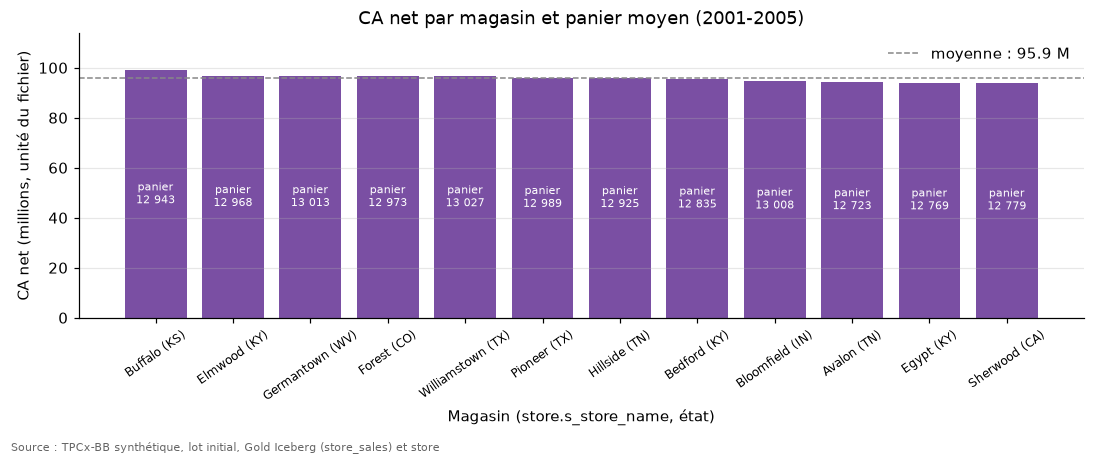

In [31]:
d = mag.sort_values("ca_net", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.2))
lib = d["s_store_name"] + " (" + d["s_state"] + ")"
ax.bar(lib, d["ca_net"] / 1e6, color="#7a4fa3")
moy = d["ca_net"].mean() / 1e6
ax.axhline(moy, color="#888", ls="--", lw=1, label=f"moyenne : {moy:.1f} M")
for i, (v, pm) in enumerate(zip(d["ca_net"] / 1e6, d["panier_moyen"])):
    ax.text(i, v / 2, f"panier\n{pm:,.0f}".replace(",", " "), ha="center", va="center", fontsize=7, color="white")
ax.set_title("CA net par magasin et panier moyen (2001-2005)")
ax.set_xlabel("Magasin (store.s_store_name, état)")
ax.set_ylabel("CA net (millions, unité du fichier)")
ax.set_ylim(0, d["ca_net"].max() / 1e6 * 1.15)
ax.tick_params(axis="x", rotation=35, labelsize=8)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right", ncols=1)
fig.text(0.01, 0.01, SOURCE + " et store", fontsize=7, color="#666")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(VIZ / "visualisation_3_magasins.png")
plt.show()

**Données, méthode, résultats, limites :**

| Élément | Contenu |
|---|---|
| Données | Gold `ventes_magasin_mensuelles` et `retours_magasin_mensuels` (retours jusqu'à 2005-12) |
| Méthode | CA, tickets, panier moyen, part du CA, taux de retour = quantité retournée / quantité vendue, par magasin |
| Résultats | CA de 94,0 M (Sherwood, CA) à 99,0 M (Buffalo, KS), soit 8,2 % à 8,6 % du total ; panier 12 723 à 13 027 ; taux de retour 2,16 % à 2,51 % |
| Limites | Retours rattachés au magasin de retour et à la date de retour ; pas de surface ni d'effectif |